In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Question 6.1

In [2]:
density_ref = 1000 #kg / m^3

P_surface = 101325 #Pa

z = np.array([-1000,-5000]) #m
g = 9.81

In [3]:
def P_z(z):
    return (P_surface - g*density_ref * z) / 101325

for solution, height in zip(P_z(z),z):
    print(f"At a depth of {-height} meters we get a pressure of {solution:.2f} atm.")

At a depth of 1000 meters we get a pressure of 97.82 atm.
At a depth of 5000 meters we get a pressure of 485.09 atm.


As we can see from the answer, pressure increases linearly with depth, as it increases with pressure around 100 atm per kilometer depth.

## Question 6.2

In [4]:
flux = 25 # W/m^2
dz = -50 # m 
dT = 1 # °C
density_fresh = 0.999e3 # Pa

def calc_dt(flux = flux,dz = dz, dT = dT,density = density_fresh):
    cw = 4.18e3

    # From the sensible heat flux equation:
    wT = flux / (density_fresh * cw) 
    dt = - (dz*dT) / (wT) 
    return dt # seconds

dt = calc_dt()

print(f"It takes {(dt / (3600*24)):.2f} days to increase the temperature by {dT} °C")

It takes 96.66 days to increase the temperature by 1 °C


In [6]:
# ???? oula had the answer

## Question 7.1

### a
Just use:

$$
p(z) = p_s + \int^\mu_z g \rho dz = p_s + g \rho_{ref} (\mu-z)
$$

and the add the latitude dependant function for mu (or whatever it's called):

$$
p(y,z)= p_s + g\rho_{ref}(\mu(y)-z)
$$

### b


Use:
$$
\frac{\partial p}{\partial y} = -fu\rho_{ref}
$$
and

$$
\frac{\partial}{\partial y} p(y,z)= \frac{\partial }{\partial y}(p_s + g\rho_{ref}(\mu(z)-z)) = g \rho_{ref}S
$$

Where $S$ is the slope of $\mu(y)$, which we can determine by:

$$
S = \arctan(\frac{\mu_m}{\theta_{mid}-\theta_{min}})
$$

In our situation, $S<0$. We can say that the first two equations are equal to each other and rewrite them for $u$, which is the value we want to know:

$$
-fu\rho_{ref} = g \rho_{ref}S
$$

$$
u = -\frac{g}{fS}
$$

In [7]:
# C

nu_m = 0.1
sigma_min = 50
sigma_mid = 40

S = np.arctan(nu_m/(sigma_mid-sigma_min)/(111000)) #slope

f = 1e-4

u = -9.81/f*S
print(f"The geostrophic current is equal to {u:.3E} m/s")

The geostrophic current is equal to 8.838E-03 m/s


# Question 7.2

# Question 8.1

In [10]:
diffusivity = 1e-5
z = -1e3
 
veloc = -40

time = z/veloc
print(f"It takes {time} years for a particle with velocity {veloc} m/year to a parth of {z} meters")

It takes 25.0 years for a particle with velocity -40 m/year to a parth of -1000.0 meters


# Question 8.2

# 8.3

In [ ]:
Ly=5e6
density_ref = 1000
tau_s = 0.1

def beta(phi):
    omega = 7.29e-5
    a = 6371e3
    return 2 * omega * a *np.cos(phi)

b = beta(np.deg2rad(35))

V = 1/b * (tau_s*np.pi)/(density_ref*Ly)*np.sin(np.pi * )

# 9.1

In [84]:
# a

def q(k,rho_f,alpha,F,dT,beta):
    a = k*rho_f*alpha * dT / 2

    q1 = a+np.sqrt(a**2-F*k*rho_f*beta)
    q2 = a-np.sqrt(a**2+F*k*rho_f*beta)

    return q1, q2

In [85]:
k = 12
rho_f = 1000
alpha = 1e-3
F = np.linspace(0,0.4,int(1e4))
dT = 10
beta = 1

q1,q2 = q(k,rho_f,alpha,F,dT,beta)

q1_nor = q1/q1[0]
q2_nor = q2/q1[0]

/var/folders/k9/db40v6y15jq4qmgtynngdxrm0000gn/T/ipykernel_3999/1197117052.py:6: RuntimeWarning: invalid value encountered in sqrt
  q1 = a+np.sqrt(a**2-F*k*rho_f*beta)


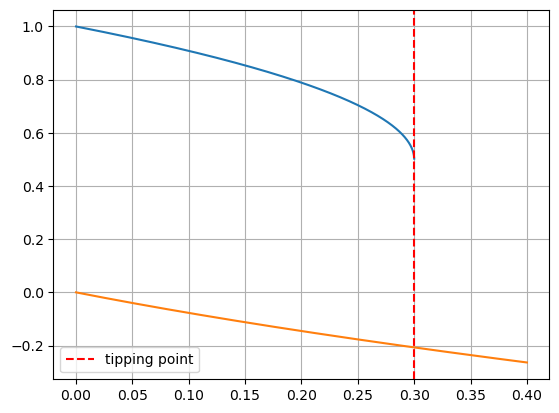

In [86]:
plt.plot(F,q1_nor)
plt.plot(F,q2_nor)

a = k*rho_f*alpha * dT / 2
b = -k*rho_f*beta

plt.axvline(-a**2/b,c='r',linestyle = '--',label='tipping point')

plt.grid()
plt.legend()

In [87]:
# b
k = 12
rho_f = 1000
alpha = 1e-3
F = 0.1
dT = np.linspace(10,20)
beta = 1

q1,q2 = q(k,rho_f,alpha,F,dT,beta)

q1_nor = q1/q1[0]
q2_nor = q2/q1[0]

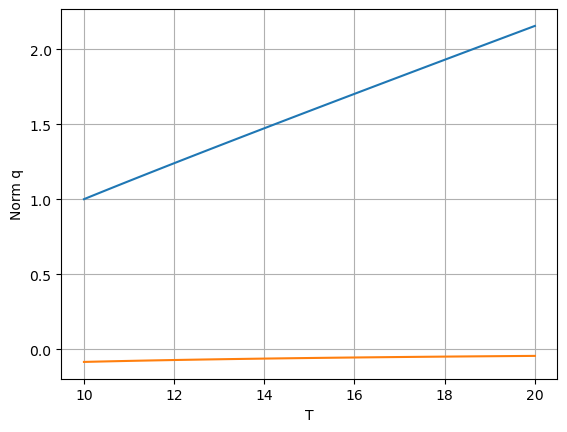

In [88]:
plt.plot(dT,q1_nor)
plt.plot(dT,q2_nor)

plt.xlabel("T")
plt.ylabel('Norm q')

plt.grid()